In [1]:
import sys
import torch
if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

In [2]:
!pip install numpy matplotlib opencv-python networkx tqdm
!pip install pytorch-lightning

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 8.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 12.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [pytorch-lightning]


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
import networkx as nx
from tqdm import tqdm
import torch

In [4]:
import os
folders = [
    "maps",
    "dataset",
    "models",
    "results"
]
for folder in folders:
    os.makedirs(folder, exist_ok=True)
print("✅ Project folders created")

✅ Project folders created


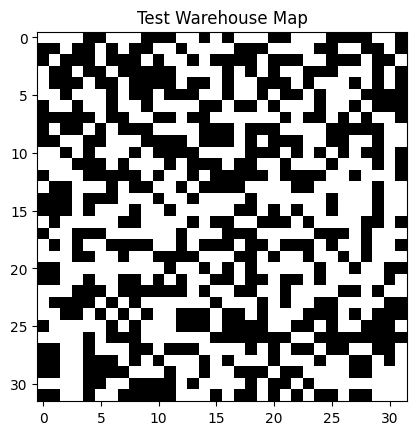

✅ Map saved in maps/test_map.png


In [5]:
import numpy as np
import matplotlib.pyplot as plt
sample_map = np.random.randint(0, 2, (32, 32))
plt.imshow(sample_map, cmap="gray")
plt.title("Test Warehouse Map")
plt.savefig("maps/test_map.png")
plt.show()
print("✅ Map saved in maps/test_map.png")

In [ ]:
!git clone https://github.com/omron-sinicx/neural-astar.git

In [2]:
%cd neural-astar

[Errno 2] No such file or directory: 'neural-astar'
/content


In [37]:
!pip install torch torchvision
!pip install numpy matplotlib scipy tqdm hydra-core

In [44]:
import sys
sys.path.append('/content/neural-astar/src')
print(sys.path[-1])

/content/neural-astar/src


In [45]:
import neural_astar
print("✅ Import successful")

✅ Import successful


In [49]:
!pip install segmentation-models-pytorch
!pip install pytorch-lightning
!pip install timm
!pip install einops

In [51]:
!find . -type f | grep -E "\.pth|\.ckpt|\.pt"

./model/mazes_032_moore_c8/lightning_logs/version_0/checkpoints/epoch=33-step=272.ckpt


In [52]:
!find . -type f | grep gif

./assets/astar.gif
./assets/neural_astar.gif
./scripts/config/create_gif.yaml
./scripts/create_gif.py


In [53]:
!find . -type f | grep png

./assets/warcraft.png


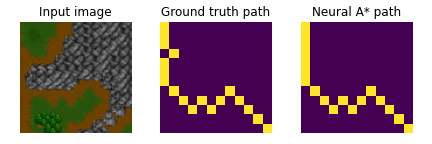

In [56]:
from IPython.display import Image
Image("assets/warcraft.png")

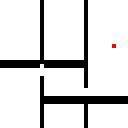

In [57]:
from IPython.display import Image
Image("assets/neural_astar.gif")

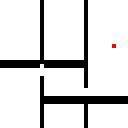

In [58]:
from IPython.display import Image
Image("assets/astar.gif")

D2 - Procedural Warehouse Map Generator

In [59]:
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs("maps32", exist_ok=True)
os.makedirs("maps64", exist_ok=True)

def generate_warehouse(size, seed):
    np.random.seed(seed)

    grid = np.zeros((size, size))

    # outer walls
    grid[0,:] = 1
    grid[-1,:] = 1
    grid[:,0] = 1
    grid[:,-1] = 1

    num_shelves = size // 8

    for i in range(num_shelves):
        col = np.random.randint(4, size-4)

        for row in range(2, size-2):
            grid[row,col] = 1

        # aisle openings
        gaps = np.random.choice(
            range(3,size-3),
            size=3,
            replace=False
        )

        for g in gaps:
            grid[g-1:g+2,col] = 0

    return grid

In [60]:
for i in range(10):
    m32 = generate_warehouse(32, i)
    np.save(
        f"maps32/map32_{i}.npy",
        m32
    )
for i in range(10):
    m64 = generate_warehouse(64, i)
    np.save(
        f"maps64/map64_{i}.npy",
        m64
    )
print("✅ 20 maps generated")

✅ 20 maps generated


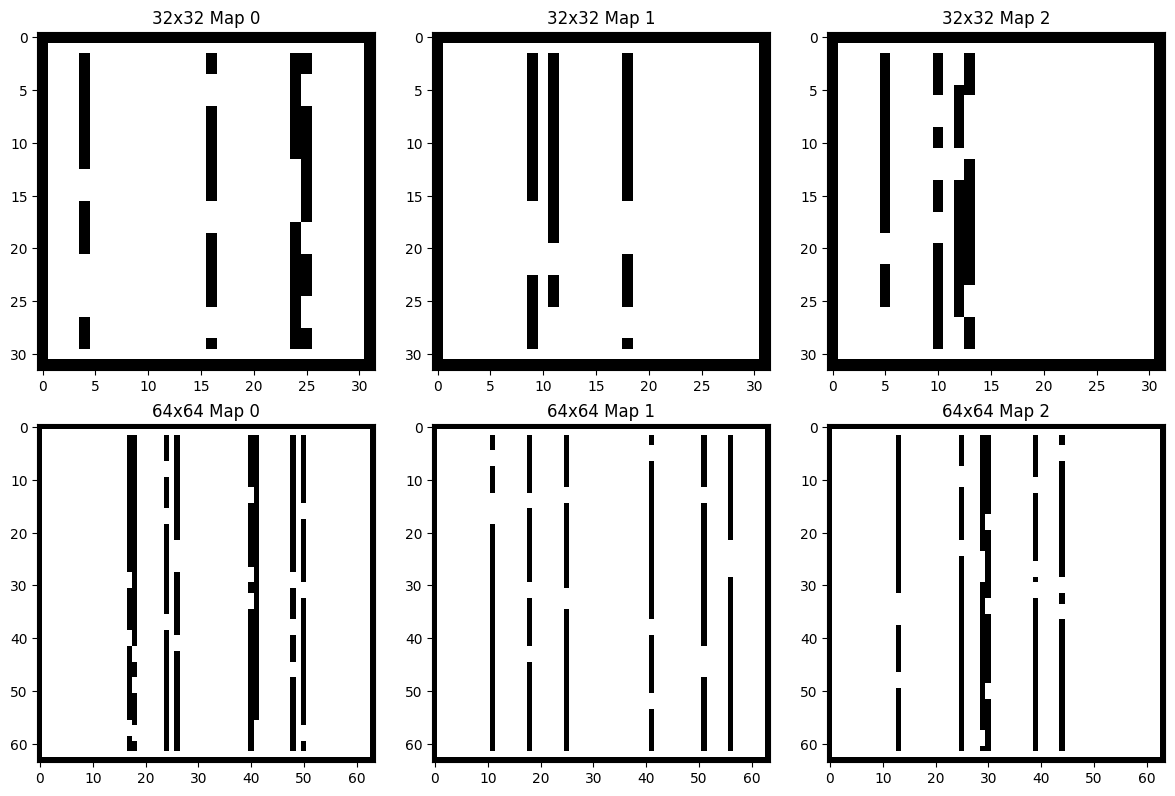

In [61]:
fig, axes = plt.subplots(2,3, figsize=(12,8))
for i in range(3):
    grid = np.load(f"maps32/map32_{i}.npy")
    axes[0,i].imshow(
        grid,
        cmap="gray_r"
    )
    axes[0,i].set_title(
        f"32x32 Map {i}"
    )
for i in range(3):
    grid = np.load(f"maps64/map64_{i}.npy")
    axes[1,i].imshow(
        grid,
        cmap="gray_r"
    )
    axes[1,i].set_title(
        f"64x64 Map {i}"
    )
plt.tight_layout()
plt.show()

In [62]:
plt.savefig("warehouse_maps.png")

<Figure size 640x480 with 0 Axes>

D3 - Dataset Creation

In [63]:
import numpy as np
import random
def random_free_cell(grid):
    free_cells = np.argwhere(grid == 0)
    idx = np.random.randint(
        len(free_cells)
    )
    return tuple(free_cells[idx])

In [64]:
grid = np.load("maps32/map32_0.npy")
start = random_free_cell(grid)
goal = random_free_cell(grid)
print("Start:", start)
print("Goal:", goal)

Start: (np.int64(19), np.int64(26))
Goal: (np.int64(4), np.int64(13))


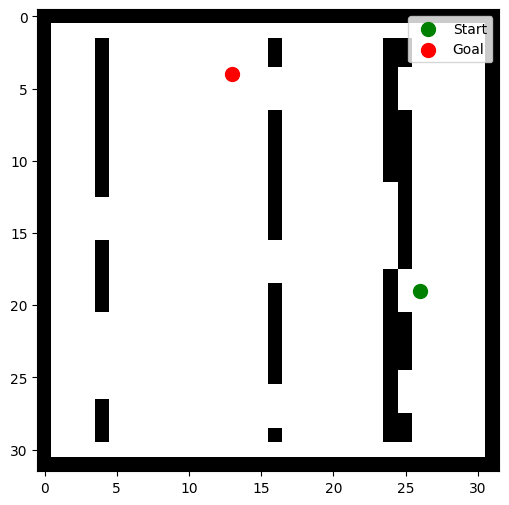

In [65]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,6))
plt.imshow(grid, cmap="gray_r")
plt.scatter(
    start[1],
    start[0],
    color='green',
    s=100,
    label='Start'
)
plt.scatter(
    goal[1],
    goal[0],
    color='red',
    s=100,
    label='Goal'
)
plt.legend()
plt.show()

D4 - Vanilla A* Baseline

In [66]:
import heapq
import numpy as np

In [67]:
def heuristic(a, b):
    return abs(a[0]-b[0]) + abs(a[1]-b[1])

In [68]:
def astar(grid, start, goal):
    rows, cols = grid.shape
    open_set = []
    heapq.heappush(
        open_set,
        (0, start)
    )
    came_from = {}
    g_score = {start:0}
    while open_set:
        current = heapq.heappop(
            open_set
        )[1]
        if current == goal:
            path = []
            while current in came_from:
                path.append(current)
                current = came_from[current]
            path.append(start)
            return path[::-1]
        for dx, dy in [
            (-1,0),
            (1,0),
            (0,-1),
            (0,1)
        ]:
            neighbor = (
                current[0]+dx,
                current[1]+dy
            )
            if (
                neighbor[0] < 0 or
                neighbor[0] >= rows or
                neighbor[1] < 0 or
                neighbor[1] >= cols
            ):
                continue
            if grid[neighbor] == 1:
                continue
            tentative_g = (
                g_score[current] + 1
            )
            if (
                neighbor not in g_score
                or tentative_g <
                g_score[neighbor]
            ):
                g_score[neighbor] = tentative_g

                f_score = (
                    tentative_g +
                    heuristic(neighbor, goal)
                )
                heapq.heappush(
                    open_set,
                    (f_score, neighbor)
                )
                came_from[neighbor] = current
    return None

In [69]:
path = astar(
    grid,
    start,
    goal
)
print(
    "Path Length:",
    len(path)
)

Path Length: 35


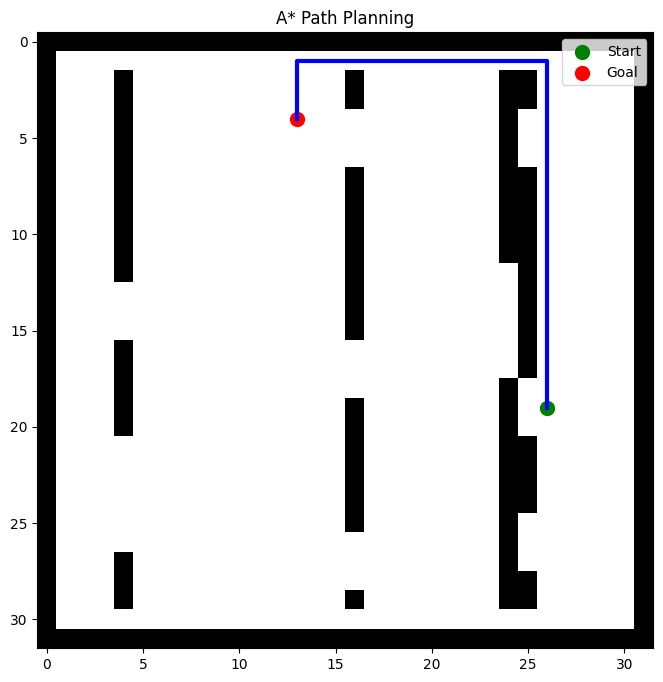

In [71]:
plt.figure(figsize=(8,8))
plt.imshow(grid, cmap="gray_r")
path = np.array(path)
plt.plot(
    path[:,1],
    path[:,0],
    color='blue',
    linewidth=3
)
plt.scatter(
    start[1],
    start[0],
    c='green',
    s=100,
    label='Start'
)
plt.scatter(
    goal[1],
    goal[0],
    c='red',
    s=100,
    label='Goal'
)
plt.legend()
plt.title(
    "A* Path Planning"
)
plt.show()

D5 - Dataset Generation

In [72]:
sample = {
    "map": grid,
    "start": start,
    "goal": goal,
    "path": path
}
print("✅ Sample Created")

✅ Sample Created


In [73]:
dataset = []
for i in range(10):
    grid = np.load(f"maps32/map32_{i}.npy")
    for j in range(20):
        start = random_free_cell(grid)
        goal = random_free_cell(grid)
        if start == goal:
            continue
        path = astar(
            grid,
            start,
            goal
        )
        if path is not None:
            dataset.append({
                "map": grid,
                "start": start,
                "goal": goal,
                "path": path
            })
print(
    "Total Samples:",
    len(dataset)
)

Total Samples: 200


In [74]:
import pickle
with open(
    "dataset.pkl",
    "wb"
) as f:
    pickle.dump(
        dataset,
        f
    )
print("✅ Dataset Saved")

✅ Dataset Saved


In [75]:
print(dataset[0].keys())

dict_keys(['map', 'start', 'goal', 'path'])


D6 - Neural Network Architecture

In [76]:
import torch
import torch.nn as nn

In [77]:
class NeuralAstar(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(
                3,
                16,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.Conv2d(
                16,
                32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.Conv2d(
                32,
                1,
                kernel_size=1
            ),
            nn.Sigmoid()
        )
    def forward(self, x):
        return self.net(x)

In [78]:
model = NeuralAstar()
print(model)

NeuralAstar(
  (net): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(32, 1, kernel_size=(1, 1), stride=(1, 1))
    (5): Sigmoid()
  )
)


In [79]:
total = sum(
    p.numel()
    for p in model.parameters()
)
print(
    "Total Parameters:",
   total
)

Total Parameters: 5121


In [80]:
dummy = torch.randn(
    1,
    3,
    32,
    32
)
out = model(dummy)
print(
    "Output Shape:",
    out.shape
)

Output Shape: torch.Size([1, 1, 32, 32])


D7 - Data Preparation

In [81]:
import torch
import numpy as np

In [82]:
sample = dataset[0]

grid = sample["map"]
start = sample["start"]
goal = sample["goal"]
path = sample["path"]

In [83]:
start_channel = np.zeros_like(grid)
start_channel[
    start[0],
    start[1]
] = 1

In [84]:
goal_channel = np.zeros_like(grid)
goal_channel[
    goal[0],
    goal[1]
] = 1

In [85]:
target = np.zeros_like(grid)
for r, c in path:
    target[r, c] = 1

In [86]:
input_tensor = np.stack([
    grid,
    start_channel,
    goal_channel
])
print(
    input_tensor.shape
)

(3, 32, 32)


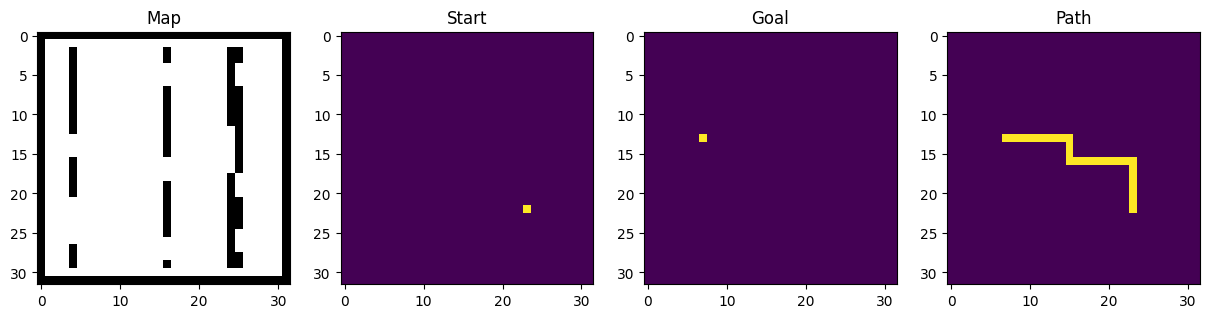

In [87]:
fig, ax = plt.subplots(
    1,
    4,
    figsize=(15,5)
)
ax[0].imshow(grid,cmap="gray_r")
ax[0].set_title("Map")
ax[1].imshow(start_channel)
ax[1].set_title("Start")
ax[2].imshow(goal_channel)
ax[2].set_title("Goal")
ax[3].imshow(target)
ax[3].set_title("Path")
plt.show()

D8 - Neural Network Training

In [88]:
x = torch.tensor(
    input_tensor,
    dtype=torch.float32
).unsqueeze(0)
y = torch.tensor(
    target,
    dtype=torch.float32
).unsqueeze(0).unsqueeze(0)
print(x.shape)
print(y.shape)

torch.Size([1, 3, 32, 32])
torch.Size([1, 1, 32, 32])


In [89]:
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [90]:
losses = []
for epoch in range(50):
    optimizer.zero_grad()
    pred = model(x)
    loss = criterion(
        pred,
        y
    )
    loss.backward()
    optimizer.step()
    losses.append(
        loss.item()
    )
    if epoch % 5 == 0:
        print(
            f"Epoch {epoch}: "
            f"{loss.item():.4f}"
        )

Epoch 0: 0.7023
Epoch 5: 0.6690
Epoch 10: 0.6372
Epoch 15: 0.5984
Epoch 20: 0.5490
Epoch 25: 0.4897
Epoch 30: 0.4226
Epoch 35: 0.3531
Epoch 40: 0.2878
Epoch 45: 0.2327


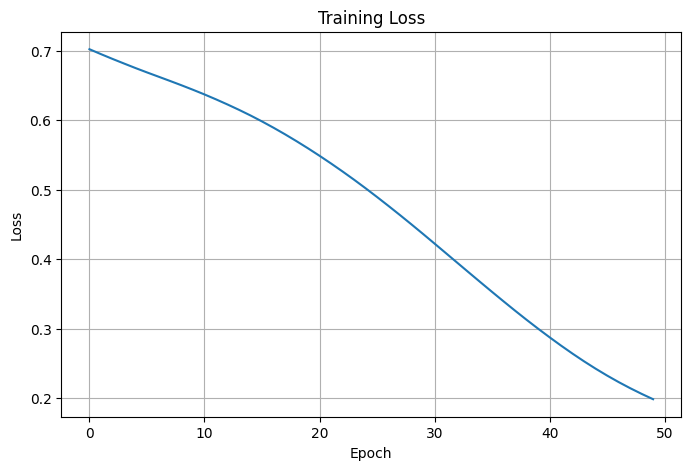

In [91]:
plt.figure(figsize=(8,5))
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(
    "Training Loss"
)
plt.grid()
plt.show()

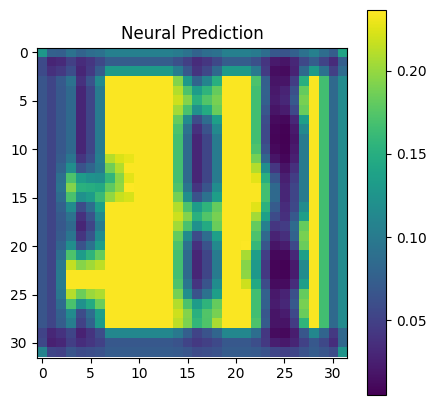

In [92]:
pred = model(x)
pred = pred.detach().numpy()
plt.figure(figsize=(5,5))
plt.imshow(
    pred[0,0]
)
plt.colorbar()
plt.title(
    "Neural Prediction"
)
plt.show()

D9 - Model Evaluation

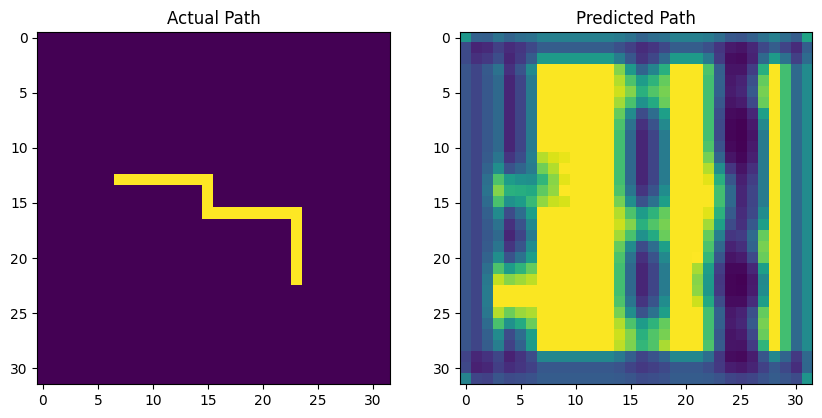

In [93]:
fig, ax = plt.subplots(
    1,
    2,
    figsize=(10,5)
)
ax[0].imshow(target)
ax[0].set_title(
    "Actual Path"
)
ax[1].imshow(pred[0,0])
ax[1].set_title(
    "Predicted Path"
)
plt.show()

In [94]:
mse = np.mean(
    (
        pred[0,0] -
        target
    )**2
)
print(
    "MSE:",
    mse
)

MSE: 0.0408570470236967


In [95]:
print(
    "Prediction Min:",
    pred.min()
)
print(
    "Prediction Max:",
    pred.max()
)

Prediction Min: 0.0052084858
Prediction Max: 0.23640233


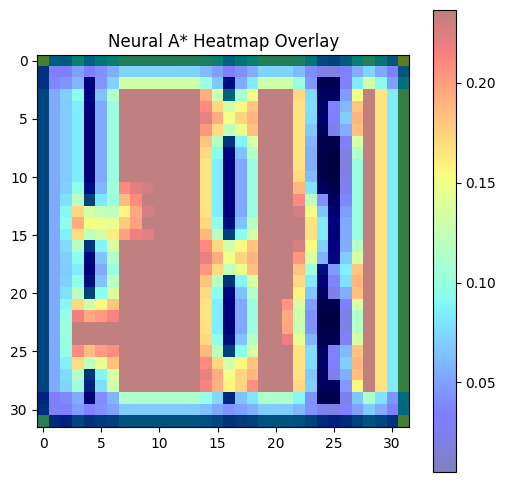

In [96]:
plt.figure(figsize=(6,6))
plt.imshow(grid, cmap="gray_r")
heatmap = pred[0,0]
plt.imshow(
    heatmap,
    alpha=0.5,
    cmap="jet"
)
plt.title(
    "Neural A* Heatmap Overlay"
)
plt.colorbar()
plt.show()

In [97]:
torch.save(
    model.state_dict(),
    "neural_astar_model.pth"
)
print("✅ Model Saved")

✅ Model Saved


In [99]:
plt.savefig("neural_astar_heatmap.png")

<Figure size 640x480 with 0 Axes>

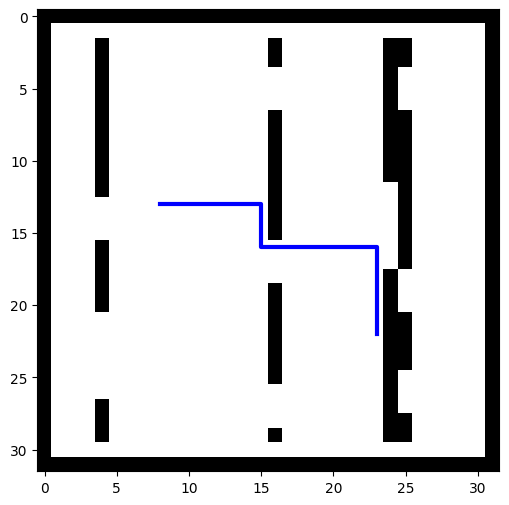

In [100]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
fig, ax = plt.subplots(figsize=(6,6))
ax.imshow(grid, cmap="gray_r")
path_array = np.array(path)
line, = ax.plot([], [],
                color='blue',
                linewidth=3)
def update(frame):

    line.set_data(
        path_array[:frame,1],
        path_array[:frame,0]
    )
    return line,
anim = FuncAnimation(
    fig,
    update,
    frames=len(path_array),
    interval=100,
    blit=True
)
HTML(anim.to_jshtml())

In [101]:
ax.scatter(
    start[1],
    start[0],
    color='lime',
    s=200,
    label='START'
)
ax.scatter(
    goal[1],
    goal[0],
    color='red',
    s=200,
    label='GOAL'
)

In [103]:
robot, = ax.plot(
    [],
    [],
    'bo',
    markersize=10
)

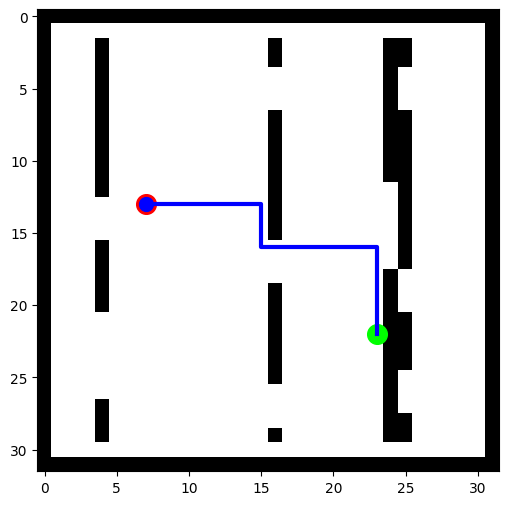

In [104]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
fig, ax = plt.subplots(figsize=(6,6))
ax.imshow(grid, cmap="gray_r")
# Start point
ax.scatter(
    start[1],
    start[0],
    color="lime",
    s=200,
    label="START"
)
# Goal point
ax.scatter(
    goal[1],
    goal[0],
    color="red",
    s=200,
    label="GOAL"
)
path_array = np.array(path)
line, = ax.plot(
    [],
    [],
    color='blue',
    linewidth=3
)
robot, = ax.plot(
    [],
    [],
    'bo',
    markersize=10
)
def update(frame):
    line.set_data(
        path_array[:frame+1,1],
        path_array[:frame+1,0]
    )
    robot.set_data(
        [path_array[frame,1]],
        [path_array[frame,0]]
    )
    return line, robot
anim = FuncAnimation(
    fig,
    update,
    frames=len(path_array),
    interval=200,
    blit=True
)
HTML(anim.to_jshtml())